In [ ]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

campagnes = ['campagne_honey']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

Lecture des données réalisée en 21.76553s


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


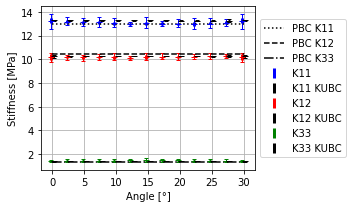

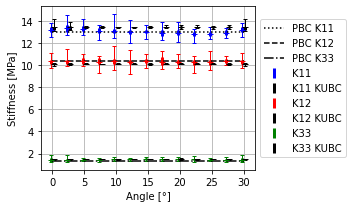

In [4]:
data_scale_7 = get_tests_by_test_id(data, index=1, target='7')
data_scale_8 = get_tests_by_test_id(data, index=1, target='8')
data_scale_9 = get_tests_by_test_id(data, index=1, target='9')
data_scale_10 = get_tests_by_test_id(data, index=1, target='10')
data_scale_11 = get_tests_by_test_id(data, index=1, target='11')
data_scale_12 = get_tests_by_test_id(data, index=1, target='12')
data_scale_13 = get_tests_by_test_id(data, index=1, target='13')
plot_coef_matrix_per_angle(data_scale_7, (12, 7, 10, 5), angle_max=30.0)
plt.savefig('images/map_honey_coef_7.pdf')
plot_coef_matrix_per_angle(data_scale_13, (12, 7, 10, 5), angle_max=30.0)
plt.savefig('images/map_honey_coef_13.pdf')


# Début étude position support-poutre

In [16]:
# %matplotlib

exit()

def get_circle(center, radius: float, PIC_SIZE) -> list[list]:
    """return a list of pix """
    center = np.array(center)
    l = []
    N = 500
    for i in range(N):
        x = int(center[0]+radius*cos(2*pi*i/N))
        y = int(center[1]+radius*sin(2*pi*i/N))
        if [x, y] not in l and x >= 0 and y >= 0 and x < PIC_SIZE and y < PIC_SIZE:
            l.append([x, y])
    return l


def init_pix():
    DIST_FROM_EDGE = 10.0
    SMALL_RADIUS = 13.0
    BIG_RADIUS = 16.0
    DIST_FROM_CORNER_EDGE = 18.0
    PAS = 28.0
    L = 288.0

    PIC_SIZE = 743  # square shape
    SCALE = PIC_SIZE/L
    centers = np.zeros((4, 10, 2))
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 1:
                x = - cyl*PAS*SCALE + (L-DIST_FROM_CORNER_EDGE)*SCALE
                y = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 1 else -DIST_FROM_EDGE*SCALE
            else:
                x = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 0 else -DIST_FROM_EDGE*SCALE
                y = cyl*PAS*SCALE + DIST_FROM_CORNER_EDGE*SCALE
            centers[cote, cyl, :] = np.array([int(x), int(y)])
    supports_lists = [[], [], [], []]

    for co in range(4):
        for cy in range(10):
            pix_list = get_circle(
                centers[co, cy, :], 1.06*SCALE*BIG_RADIUS, PIC_SIZE)
            if co % 2 == 0:
                pix_list = sorted(pix_list, key=lambda x: x[1])
            else:
                pix_list = sorted(pix_list, key=lambda x: x[0])

            supports_lists[co].append(Support(pix_list))

    return supports_lists


def draw_circle(img, pix_list, val=0.0):
    for p in pix_list:
        img[p[0], p[1]] = val
    return img


class Support:
    def __init__(self, pix_list) -> None:
        self.pix_list = pix_list


def compute_support_links(test, supports_lists):
    support_links = np.zeros((4, 10))
    support_links[:] = np.nan
    for co in range(4):
        for cy in range(10):
            if cy not in test.skipped_cyl[co]:
                pix_list = supports_lists[co][cy].pix_list
                img = test.get_geo()
                s = 0
                s_counter = 0.0
                for i, p in enumerate(pix_list):
                    if img[p[0], p[1]] == 1.0:
                        s += i
                        s_counter += 1
                moyenne = int(s/s_counter)
                support_links[co, cy] = moyenne/len(pix_list)-0.5
                # img2[pix_list[moyenne][0],pix_list[moyenne][1]]=0.5
    test.support_links = support_links
    return support_links


def compute_ms2(test:Test, supports_lists):
    additional_ms=0
    for co in range(4):
        for cy in range(10):
            if cy not in test.skipped_cyl[co]:
                pix_list = supports_lists[co][cy].pix_list
                img = test.get_geo()
                
                flag=False
                crit = 0.25 # eg 0.25 -> need matter between 25% and 75% of the arc to validate the support.
                for i, p in enumerate(pix_list):
                    if img[p[0], p[1]] == 1.0 and i/len(pix_list) < 1-crit and i/len(pix_list) > crit:
                        flag=True
                if not flag:
                    additional_ms+=1
    return test.get_number_ms() + additional_ms


supports_lists = init_pix()
compute_support_links(test, supports_lists)
print(test.support_links)


# ~ Trier pix_list et peut etre créer une list avec pix_list dedans


[[ 0.11363636 -0.29545455 -0.06818182  0.10227273  0.04545455  0.375
  -0.01136364         nan -0.03409091 -0.34090909]
 [ 0.09090909 -0.18181818         nan         nan  0.17045455 -0.09090909
  -0.28409091         nan  0.07954545 -0.05681818]
 [        nan -0.11111111 -0.36666667  0.15555556 -0.28888889  0.17777778
  -0.05555556  0.27777778         nan  0.01111111]
 [-0.03333333 -0.38888889         nan  0.24444444 -0.01111111 -0.28888889
          nan  0.35555556  0.06666667 -0.3       ]]


In [ ]:
supports_lists = init_pix()
c=0
data_support_link_dict={}
modief_ms={}
for test_id, test in data_scale_13.items():
    support_links=compute_support_links(test, supports_lists)
    data_support_link_dict[test_id]=support_links.tolist()
    modief_ms[test_id]=compute_ms2(test, supports_lists)
    c+=1
    if c%20==0:
        print(f'{c}/{len(data_scale_7)}')

with open('tmp.json', "w") as fp:
    json.dump(data_support_link_dict, fp, indent=4, separators=(", ", ": "),
                sort_keys=True)  # encode dict into JSON

# t=data_scale_7[list(data_scale_7.keys())[1]]
# print(t.test_id)
# plt.figure(figsize=(10,10))
# t.show_geo()
# print(t.support_links)
# print(np.nanmean(t.support_links))


: 

: 

0.21852904979920534
5.49


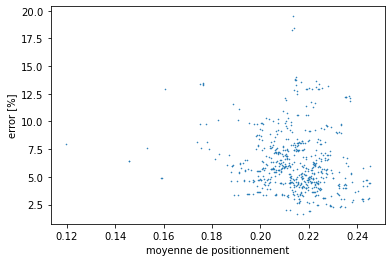

13
5.49


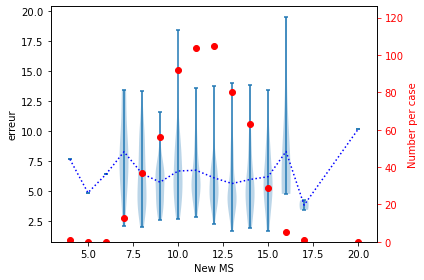

In [ ]:
x_bulk, y_bulk=[],[]
for test_id, test in data_scale_13.items():
    # x_bulk.append(modief_ms[test_id])
    x_bulk.append(np.nanstd(data_support_link_dict[test_id]))
    y_bulk.append(test.get_error((0,3)))

print(x_bulk[0])
print(y_bulk[0])
plt.scatter(x_bulk, y_bulk, s=0.3)
plt.ylabel('error [%]')
plt.xlabel('moyenne de positionnement')
plt.show()

x_bulk, y_bulk=[],[]
for test_id, test in data_scale_13.items():
    x_bulk.append(modief_ms[test_id])
    y_bulk.append(test.get_error((0,3)))

print(x_bulk[0])
print(y_bulk[0])
plot_box2(x_bulk,y_bulk, step=0.9, width=0.5, ylabel='New MS')


[[        nan -0.23863636  0.          0.28409091         nan -0.375
   0.15909091 -0.06818182 -0.09090909  0.09090909]
 [ 0.19318182  0.06818182 -0.25        0.13636364 -0.35227273         nan
   0.                 nan -0.06818182  0.18181818]
 [ 0.04444444  0.31111111         nan -0.31111111  0.01111111  0.13333333
  -0.17777778  0.3                nan -0.4       ]
 [        nan  0.17777778 -0.04444444  0.13333333 -0.32222222  0.07777778
  -0.37777778         nan -0.01111111  0.38888889]]


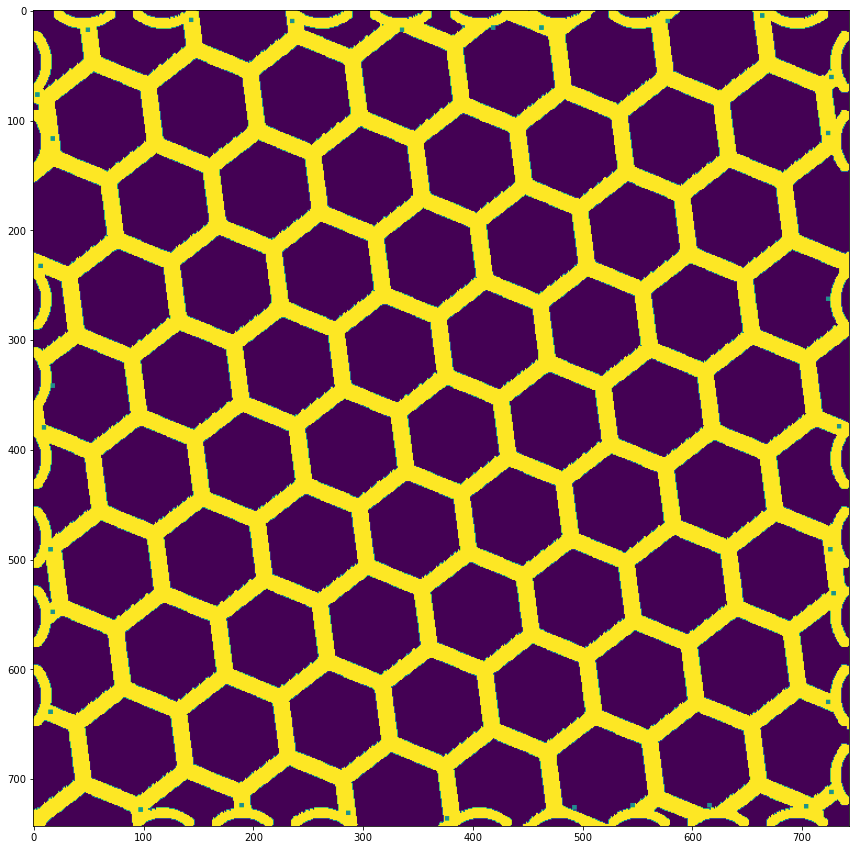

In [ ]:

# ! DEBUG
# %matplotlib


def get_circle(center, radius: float, PIC_SIZE) -> list[list]:
    """return a list of pix """
    center = np.array(center)
    l = []
    N = 500
    for i in range(N):
        x = int(center[0]+radius*cos(2*pi*i/N))
        y = int(center[1]+radius*sin(2*pi*i/N))
        if [x, y] not in l and x >= 0 and y >= 0 and x < PIC_SIZE and y < PIC_SIZE:
            l.append([x, y])
    return l


def init_pix():
    DIST_FROM_EDGE = 10.0
    SMALL_RADIUS = 13.0
    BIG_RADIUS = 16.0
    DIST_FROM_CORNER_EDGE = 18.0
    PAS = 28.0
    L = 288.0

    PIC_SIZE = 743  # square shape
    SCALE = PIC_SIZE/L
    centers = np.zeros((4, 10, 2))
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 1:
                x = - cyl*PAS*SCALE + (L-DIST_FROM_CORNER_EDGE)*SCALE
                y = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 1 else -DIST_FROM_EDGE*SCALE
            else:
                x = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 0 else -DIST_FROM_EDGE*SCALE
                y = cyl*PAS*SCALE + DIST_FROM_CORNER_EDGE*SCALE
            centers[cote, cyl, :] = np.array([int(x), int(y)])
    supports_lists = [[], [], [], []]

    for co in range(4):
        for cy in range(10):
            pix_list = get_circle(
                centers[co, cy, :], 1.06*SCALE*BIG_RADIUS, PIC_SIZE)
            if co % 2 == 0:
                pix_list = sorted(pix_list, key=lambda x: x[1])
            else:
                pix_list = sorted(pix_list, key=lambda x: x[0])

            supports_lists[co].append(Support(pix_list))

    return supports_lists


def draw_circle(img, pix_list, val=0.0):
    for p in pix_list:
        img[p[0], p[1]] = val
    return img


class Support:
    def __init__(self, pix_list) -> None:
        self.pix_list = pix_list


def compute_support_links(test, supports_lists):
    support_links = np.zeros((4, 10))
    support_links[:] = np.nan
    for co in range(4):
        for cy in range(10):
            if cy not in test.skipped_cyl[co]:
                pix_list = supports_lists[co][cy].pix_list
                img = test.get_geo()
                s = 0
                s_counter = 0.0
                for i, p in enumerate(pix_list):
                    if img[p[0], p[1]] == 1.0:
                        s += i
                        s_counter += 1
                moyenne = int(s/s_counter)
                support_links[co, cy] = moyenne/len(pix_list)-0.5
                img2[pix_list[moyenne][0]-2:pix_list[moyenne][0]+2,
                     pix_list[moyenne][1]-2:pix_list[moyenne][1]+2]=0.5
    test.support_links = support_links
    return support_links

t=data_scale_7[list(data_scale_7.keys())[1]]
img = test.get_geo()
img2=np.copy(img)
supports_lists = init_pix()
print(compute_support_links(test, supports_lists))
plt.figure(figsize=(15,15))
plt.imshow(img2)

# Regles de conception

- Choisir un motif de petite taille 
- Ne pas aligner le motif sur le cadre (eg 0° ou 30° pour le nida)
- Faire une découpe dans les coins mais ne pas couper une barre dans sa longueur
- quitte à perdre un cylindre, il vaut mieux ne pas le perdre dans le coins en haut à droite et en  bas à gauche
  